# Autoencoders and Keras API

The key idea of image generation is to develop a low-dimensional latent space of representations (which naturally is a vector space) where any point can be mapped to a realistic-looking image. The module capable of realizing this mapping, taking as input a latent point and outputting an image (a grid of pixels), is called a decoder (in autoencoders) or a generator (in Generative Adversarial Networks).

A classical image autoencoder takes an image, maps it to a latent vector space via an encoder module, and then decodes it back to an output with the same dimensions as the original image. It’s then trained by using as target data the same images as the input images, meaning the autoencoder learns to reconstruct the original inputs. Most commonly, you’ll constrain the code to be low-dimensional, in which case the encoder acts as a way to compress the input data into fewer bits of information.

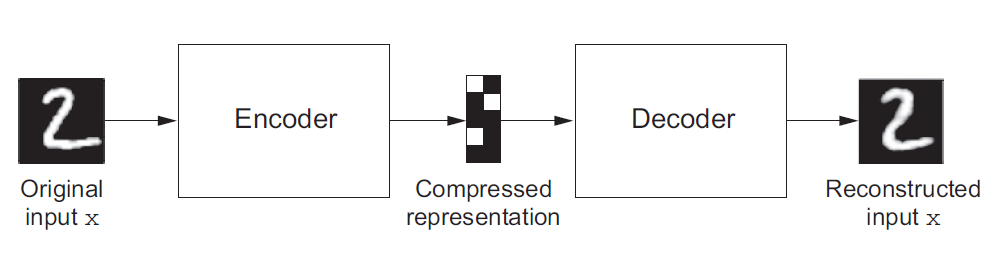

# Simple autoencoder

We'll start with a single fully-connected neural layer as an encoder and as a decoder.

Let's prepare our input data. We're using MNIST digits, and we're discarding the labels (since we're only interested in encoding/decoding the input images).

We will normalize all values between 0 and 1 and we will flatten the 28×28 images into vectors of size 784.

In [1]:
from tensorflow.keras.datasets import mnist
import numpy as np

(x_train, _), (x_test, _) = mnist.load_data()

x_train = x_train.astype("float32") / 255.
x_train = x_train.reshape(len(x_train), 28 * 28)

x_test = x_test.astype("float32") / 255.
x_test = x_test.reshape(len(x_test), 28 * 28)

I0000 00:00:1795002702.258664    7983 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795002702.303779    7983 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795002705.707413    7983 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


It is time to prepare the model itself. However, before we will do it let's notice that we won't use common `models.Sequential()` at the beginning. All neural networks introduced before have been implemented using the Sequential model, which makes the assumption that the network has exactly one input and exactly one output, and that it consists of a linear stack of layers. When this is not the case, we can use Keras functional API to better personalize it to our needs. In the functional API, you directly manipulate tensors, and you use layers as functions that take tensors and return tensors. Every layer is constructed like this:

`output_tensor = Layer(parameters)(input_tensor)`

By correct use of input and output variable names, we can connect them to one another. When we chain all layers together we use the Model function (with input and output variable names of the whole network as parameters) to create a complete model.

`model_name = Model(network_input_name, network_output_name)`

Our first autoencoder can be a good example of this:

In [2]:
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

# this is the size of our encoded representations
encoding_dim = 32

# this is our input placeholder
input_img = Input(shape=(784,))

# "encoded" is the encoded representation of the input
encoded = Dense(encoding_dim, activation='relu')(input_img)

# "decoded" is the lossy reconstruction of the input
decoded = Dense(784, activation='sigmoid')(encoded)

# this model maps an input to its reconstruction
autoencoder = Model(input_img, decoded)

E0000 00:00:1795002708.371193    7983 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50

I0000 00:00:1795002708.371227    7983 cuda_diagnostics.cc:171] verbose logging is disabled. Rerun with verbose logging (usually --v=1 or --vmodule=cuda_diagnostics=1) to get more diagnostic output from this module
I0000 00:00:1795002708.371232    7983 cuda_diagnostics.cc:176] retrieving CUDA diagnostic information for host: computer
I0000 00:00:1795002708.371237    7983 cuda_diagnostics.cc:183] hostname: computer
I0000 00:00:1795002708.371273    7983 cuda_diagnostics.cc:190] libcuda reported version is: NOT_FOUND: was unable to find libcuda.so DSO loaded into this program. The library may be missing or provided via another object.
I0000 00:00:1795002708.371300    7983 cuda_diagnostics.cc:194] kernel reported version is: 595.112.7


 Now, let's prepare separate models for encoder and decoder:

In [3]:
# this model maps an input to its encoded representation
encoder = Model(input_img, encoded)

# create a placeholder for an encoded (32-dimensional) input
encoded_input = Input(shape=(encoding_dim,))

# retrieve the last layer of the autoencoder model
decoder_layer = autoencoder.layers[-1]

# create the decoder model
decoder = Model(encoded_input, decoder_layer(encoded_input))

 Now let's train our autoencoder to reconstruct MNIST digits.

In [4]:
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")

autoencoder.fit(
    x_train, x_train,
    epochs=50,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

# encode and decode some digits
# note that we take them from the *test* set
encoded_imgs = encoder.predict(x_test)
decoded_imgs = decoder.predict(encoded_imgs)

Epoch 1/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.2771 - val_loss: 0.1898
Epoch 2/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1707 - val_loss: 0.1533
Epoch 3/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1433 - val_loss: 0.1328
Epoch 4/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1276 - val_loss: 0.1204
Epoch 5/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1176 - val_loss: 0.1123
Epoch 6/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1107 - val_loss: 0.1065
Epoch 7/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1057 - val_loss: 0.1025
Epoch 8/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1019 - val_loss: 0.0990
Epoch 9/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0992 - val_loss: 0.0968
Epoch 10/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0973 - val_loss: 0.0952
Epoch 11/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0960 - val_loss: 0.0943
Epoch 12/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

 We can try to visualize the reconstructed inputs and the encoded representations. We will use Matplotlib.

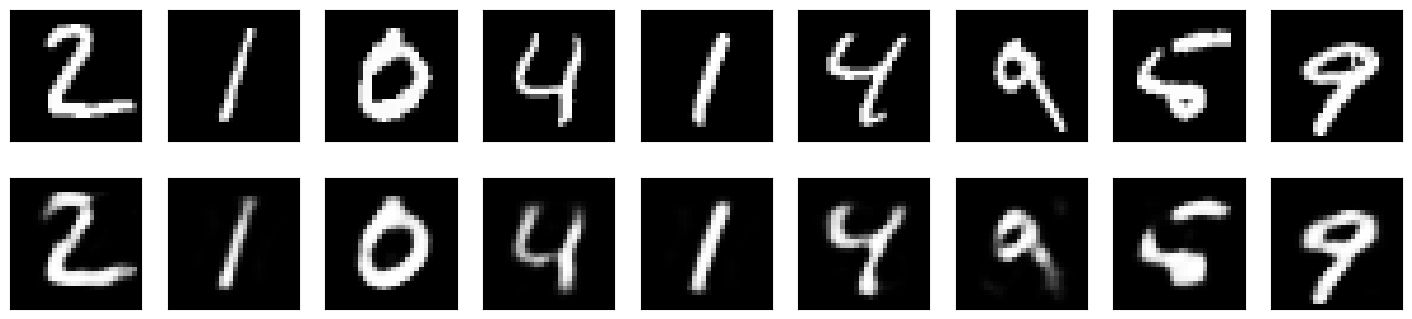

In [5]:
import matplotlib.pyplot as plt

n = 10  # how many digits we will display
plt.figure(figsize=(20, 4))
for i in range(1, n):
    # display original
    ax = plt.subplot(2, n, i)
    plt.imshow(x_test[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # display reconstruction
    ax = plt.subplot(2, n, i + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

 The top row is the original digits, and the bottom row is the reconstructed digits. We are losing quite a bit of detail with this basic approach.


# Convolutional autoencoder

Since our inputs are images, it makes sense to use convolutional neural networks (convnets) as encoders and decoders. In practical settings, autoencoders applied to images are always convolutional autoencoders –they simply perform much better.

To train it, we will again use the original MNIST digits but with shape (samples, 28, 28, 1), and we will just normalize pixel values between 0 and 1.

In [6]:
from tensorflow.keras.datasets import mnist

(x_train, _), (x_test, _) = mnist.load_data()

x_train = x_train.astype("float32") / 255.
x_test = x_test.astype("float32") / 255.

x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

 Now, let's prepare the model. The encoder will consist of a stack of Conv2D and MaxPooling2D layers (max-pooling being used for spatial down-sampling), while the decoder will consist of a stack of Conv2D and UpSampling2D layers.

In [7]:
from tensorflow.keras.layers import Input, Dense, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.models import Model
from tensorflow.keras import backend as K

input_img = Input(shape=(28, 28, 1))  # adapt this if using `channels_first` image data format

x = Conv2D(16, (3, 3), activation='relu', padding='same')(input_img)
x = MaxPooling2D((2, 2), padding='same')(x)
x = Conv2D(8, (3, 3), activation='relu', padding='same')(x)
x = MaxPooling2D((2, 2), padding='same')(x)
x = Conv2D(8, (3, 3), activation='relu', padding='same')(x)
encoded = MaxPooling2D((2, 2), padding='same')(x)

# at this point the representation is (4, 4, 8) i.e. 128-dimensional

x = Conv2D(8, (3, 3), activation='relu', padding='same')(encoded)
x = UpSampling2D((2, 2))(x)
x = Conv2D(8, (3, 3), activation='relu', padding='same')(x)
x = UpSampling2D((2, 2))(x)
x = Conv2D(16, (3, 3), activation='relu')(x)
x = UpSampling2D((2, 2))(x)
decoded = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

autoencoder = Model(input_img, decoded)

autoencoder.compile(optimizer="adam", loss="binary_crossentropy")

autoencoder.fit(
    x_train, x_train,
    epochs=10,
    batch_size=128,
    shuffle=True,
    validation_data=(x_test, x_test)
)

decoded_imgs = autoencoder.predict(x_test)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 40ms/step - loss: 0.2224 - val_loss: 0.1554
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - loss: 0.1450 - val_loss: 0.1364
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - loss: 0.1334 - val_loss: 0.1282
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - loss: 0.1270 - val_loss: 0.1238
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - loss: 0.1223 - val_loss: 0.1191
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - loss: 0.1188 - val_loss: 0.1159
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - loss: 0.1160 - val_loss: 0.1134
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - loss: 0.1138 - val_loss: 0.1117
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - loss: 0.1120 - val_loss: 0.1101
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - loss: 0.1105 - val_loss: 0.1087
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


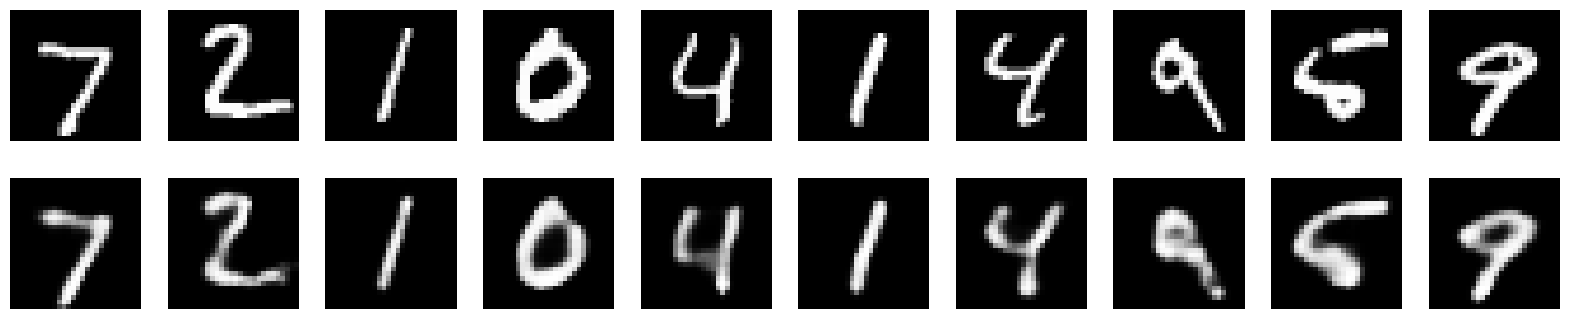

In [8]:
import matplotlib.pyplot as plt

n = 10
plt.figure(figsize=(20, 4))

for i in range(n):
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    ax.axis("off")

    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.show()

# Bonus Task 1 - Generative Adversarial Network and other models

Autoenkoders were one of the first models used for Generative AI. All modern solutions originate from this idea.

Recent tool, such as those used by LLMs are based on architectures such as Generative Adversarial Networks (GAN) or Diffusion Models (StableDiffusion).

If you would like to train your own GAN model for a specific task, check this notebook:
[GAN network notebook](https://colab.research.google.com/github/timsainb/tensorflow2-generative-models/blob/master/2.0-GAN-fashion-mnist.ipynb#scrollTo=erd_AwiMOlLn).

# Bonus Task 2 - Autoencoders as a solution for unlabelled data.

One of the common scenarios in deep learning is having a huge dataset, but only labels for some of them. One of the idea to adress this issue can be done with autoencoders. It is simmilar to transfer learning, but instead of using a pre-train model, we can train some early layers in an unsupervised setting. It goas as follows:

1. Define a convolutional autoencoder
2. Train on a large amount of unlabelled data to reconstruct itself (unsupervised learning)
3. Cut the model in half to separate encoder and decoder
4. Froze the encoder part
5. Add dense classifier on top
6. Train the model on a small amount of labelled  data (supervised learning)

You can try this task on our cats and dogs dataset from previous labs or any other dataset from Kaggle. A full 25000 dataset from Kaggle can be used as the basis for traing an unsupervised autoencoder, while our 2000 images subset can be used for classifier for direct comparison with other models (with augmentation, transfer learning etc.)





In [9]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# Image settings
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Load images with labels for the classifier.
# image_dataset_from_directory assigns labels in alphabetical order:
# cats = 0, dogs = 1.
train_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/train",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=42,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/val",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/test",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
)

print("Classes:", train_ds.class_names)

# Normalize RGB pixels to [0, 1].
def normalize(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

train_ds = train_ds.map(normalize, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_ds.map(normalize, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds = test_ds.map(normalize, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# For the autoencoder, use each image as both input and target.
# Labels are deliberately discarded here.
train_autoencoder_ds = train_ds.map(
    lambda images, labels: (images, images),
    num_parallel_calls=AUTOTUNE,
).prefetch(AUTOTUNE)

val_autoencoder_ds = val_ds.map(
    lambda images, labels: (images, images),
    num_parallel_calls=AUTOTUNE,
).prefetch(AUTOTUNE)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Classes: ['cats', 'dogs']


In [10]:
# Encoder
encoder_input = layers.Input(shape=(*IMAGE_SIZE, 3), name="image")

x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(encoder_input)
x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Conv2D(128, 3, strides=2, padding="same", activation="relu")(x)
encoded = layers.Conv2D(256, 3, strides=2, padding="same",
                        activation="relu", name="encoded")(x)

encoder = Model(encoder_input, encoded, name="encoder")

# Decoder
decoder_input = layers.Input(shape=(8, 8, 256), name="encoded_image")

x = layers.Conv2DTranspose(128, 3, strides=2, padding="same", activation="relu")(decoder_input)
x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Conv2DTranspose(16, 3, strides=2, padding="same", activation="relu")(x)
decoded = layers.Conv2D(3, 3, padding="same", activation="sigmoid", name="reconstruction")(x)

decoder = Model(decoder_input, decoded, name="decoder")

# Full autoencoder
autoencoder_input = layers.Input(shape=(*IMAGE_SIZE, 3))
autoencoder_output = decoder(encoder(autoencoder_input))
autoencoder = Model(autoencoder_input, autoencoder_output, name="autoencoder")

autoencoder.compile(optimizer="adam", loss="binary_crossentropy")
autoencoder.summary()

ae_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
    )
]

autoencoder.fit(
    train_autoencoder_ds,
    validation_data=val_autoencoder_ds,
    epochs=30,
    callbacks=ae_callbacks,
)

encoder.save("cats_dogs_encoder.keras")

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 8, 8, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 128, 128, 3)    │       392,355 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 780,771 (2.98 MB)

 Trainable params: 780,771 (2.98 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


/home/user/Documents/programming/python/PracticalAspectsOfDeepLearningCourse/lab5/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


63/63 ━━━━━━━━━━━━━━━━━━━━ 28s 411ms/step - loss: 0.6393 - val_loss: 0.5819
Epoch 2/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 24s 375ms/step - loss: 0.5712 - val_loss: 0.5655
Epoch 3/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 26s 415ms/step - loss: 0.5694 - val_loss: 0.5631
Epoch 4/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 26s 411ms/step - loss: 0.5606 - val_loss: 0.5609
Epoch 5/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 25s 400ms/step - loss: 0.5575 - val_loss: 0.5566
Epoch 6/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 25s 398ms/step - loss: 0.5552 - val_loss: 0.5544
Epoch 7/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 26s 414ms/step - loss: 0.5541 - val_loss: 0.5532
Epoch 8/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 25s 393ms/step - loss: 0.5521 - val_loss: 0.5522
Epoch 9/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 26s 408ms/step - loss: 0.5516 - val_loss: 0.5514
Epoch 10/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 26s 409ms/step - loss: 0.5518 - val_loss: 0.5534
Epoch 11/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 25s 400ms/step - loss: 0.5508 - val_loss: 0.5508
Epoch 12/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 25s 399ms/ste

In [11]:
encoder.trainable = False

classifier_input = layers.Input(shape=(*IMAGE_SIZE, 3), name="image")
features = encoder(classifier_input, training=False)
features = layers.GlobalAveragePooling2D()(features)
features = layers.Dropout(0.3)(features)
classifier_output = layers.Dense(1, activation="sigmoid", name="dog_probability")(features)

classifier = Model(classifier_input, classifier_output, name="cats_dogs_classifier")

classifier.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

classifier.summary()

classifier_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
    )
]

classifier.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=classifier_callbacks,
)

test_loss, test_accuracy = classifier.evaluate(test_ds)
print(f"Test accuracy: {test_accuracy:.3f}")

Model: "cats_dogs_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 8, 8, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dog_probability (Dense)         │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 388,673 (1.48 MB)

 Trainable params: 257 (1.00 KB)

 Non-trainable params: 388,416 (1.48 MB)

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.5030 - loss: 0.7077 - val_accuracy: 0.5240 - val_loss: 0.6901
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.5145 - loss: 0.7023 - val_accuracy: 0.5420 - val_loss: 0.6847
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.5205 - loss: 0.6975 - val_accuracy: 0.5410 - val_loss: 0.6840
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.5285 - loss: 0.6970 - val_accuracy: 0.5460 - val_loss: 0.6825
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.5300 - loss: 0.6933 - val_accuracy: 0.5520 - val_loss: 0.6806
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.5210 - loss: 0.6992 - val_accuracy: 0.5510 - val_loss: 0.6833
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.5415 - loss: 0.6896 - val_accuracy: 0.5680 - val_loss: 0.6774
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.5155 - loss: 0.6954 - val_accuracy: 0.5720 - v